# Computational exercise 10

## Exercise 1

firedrake:WARNING OMP_NUM_THREADS is not set or is set to a value greater than 1, we suggest setting OMP_NUM_THREADS=1 to improve performance
/tmp/ipykernel_82103/1164260914.py:76: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


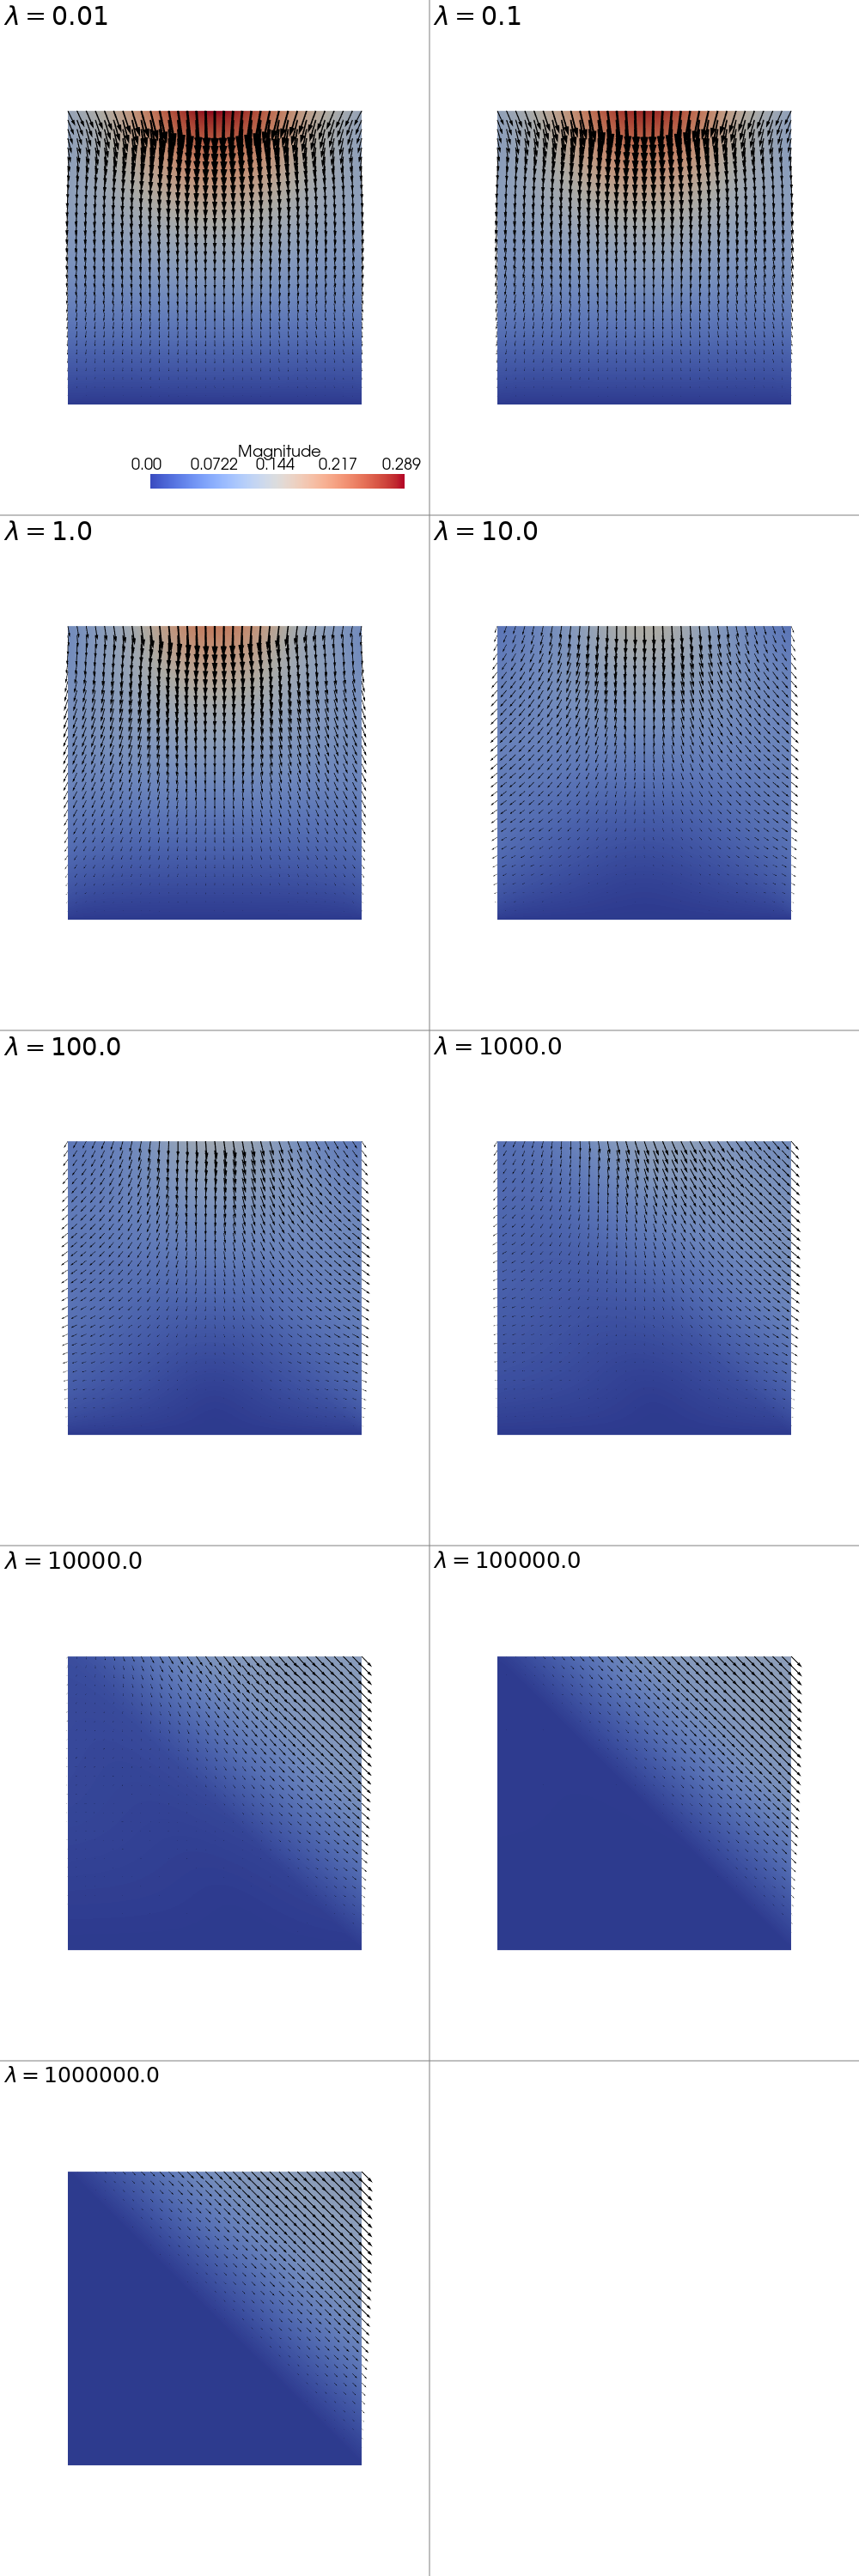

In [1]:
import firedrake as fd
from firedrake.output import VTKFile 
from firedrake.__future__ import interpolate 
import numpy as np
import pyvista as pv



def epsilon(v):
    return fd.Constant(0.5) * (fd.grad(v) + fd.grad(v).T)


def solve(mesh, Vh, bcs, lamb, srfc_f, bd_f, save_name, plot):
    u, v = fd.TrialFunction(Vh), fd.TestFunction(Vh)

    bclst = []
    for key in bcs:
        bclst.append(fd.DirichletBC(Vh, bcs[key], tags[key]))

    a = (2.0 * viscosity() * fd.inner(epsilon(u), epsilon(v)) + lamb * fd.div(u) * fd.div(v)) * fd.dx
    L = fd.inner(bd_f, v) * fd.dx + fd.inner(srfc_f, v) * fd.ds(tags['Top'])


    uh = fd.Function(Vh, name="u")

    opts={"ksp_type": "preonly", "pc_type": "lu"}
    fd.solve(a == L, uh, bcs=bclst, solver_parameters=opts)

    VTKFile(save_name).write(uh)
    return uh

# Finite element mesh
Nx, Ny = 32, 32
Lx, Ly = 1.0, 1.0
mesh = fd.RectangleMesh(Nx, Ny, Lx, Ly, quadrilateral=False)
tags = {'Bottom': 3, 'Top': 4, 'Left': 1, 'Right': 2}

def viscosity():
    return fd.Constant(1.0)

x = fd.SpatialCoordinate(mesh)

body_force = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])
surface_force = fd.as_vector([fd.Constant(0.0), -fd.exp(-20.0*(x[0]-0.5*Lx)**2)])
noslip = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])

mybcs = {'Bottom': noslip}

lamblst = [1.0e-2, 1.0e-1, 1.0, 10.0, 100.0, 1000.0, 1.0e4, 1.0e5, 1.0e6]

Vh = fd.VectorFunctionSpace(mesh, 'CG', degree=1, dim=2)

plotter = pv.Plotter(shape=(5, 2), window_size=(1000,3000))

for i, lamb in enumerate(lamblst):
    save_name = f"Solutions/ex_1_lamb={lamb}.pvd"
    uh = solve(mesh, Vh, mybcs, lamb, surface_force, body_force, save_name, True)
    
    grid = pv.read(save_name)
    grid = grid.combine(merge_points=True)
    u = grid.point_data["u"]
    grid.point_data["Magnitude"] = np.linalg.norm(u, axis=1)

    arrows = grid.glyph(
        orient="u",
        scale="u",
        factor=0.5
    )
    plotter.subplot(i//2, i%2)
    plotter.add_mesh(grid, scalars="Magnitude", cmap="coolwarm", opacity=1.0, show_edges=False)
    plotter.add_mesh(arrows, color="black")
    plotter.add_text(rf"$\lambda = {lamb}$", font_size=12)
    plotter.view_xy()

plotter.link_views()
plotter.show()


## Exercise 2

lambda = 1.00e-02, area = 0.8183633756
lambda = 1.00e-01, area = 0.8303796735
lambda = 1.00e+00, area = 0.8967129238
lambda = 1.00e+01, area = 0.9743571275
lambda = 1.00e+02, area = 0.9910889340
lambda = 1.00e+03, area = 0.9941921565
lambda = 1.00e+04, area = 0.9981256369
lambda = 1.00e+05, area = 0.9997483657
lambda = 1.00e+06, area = 0.9999739071


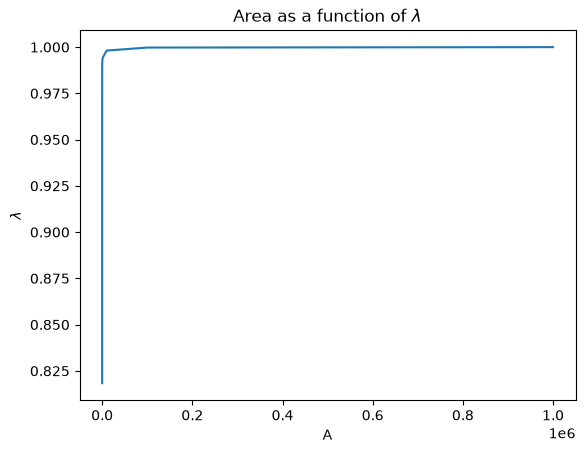

In [2]:
import matplotlib.pyplot as plt

#https://www.firedrakeproject.org/mesh-coordinates.html

# Store the original mesh coordinates
X0 = fd.Function(mesh.coordinates.function_space())
X0.assign(mesh.coordinates)

areas = []

for i, lamb in enumerate(lamblst):

    save_name = f"Solutions/ex_1_lamb={lamb}.pvd"

    # Solve on the original configuration
    uh = solve(
        mesh, Vh, mybcs, lamb,
        surface_force, body_force,
        save_name, True
    )

    # Move mesh nodes: x = X + u(X)
    mesh.coordinates.assign(X0 + uh)

    # Compute the area of the deformed configuration
    A = fd.assemble(1.0 * fd.dx(domain=mesh))
    areas.append(A)

    # Save the deformed configuration
    VTKFile(
        f"Solutions/deformed_lamb={lamb}.pvd"
    ).write(uh)

    print(f"lambda = {lamb:.2e}, area = {A:.10f}")

    # Restore the original configuration
    mesh.coordinates.assign(X0)

fig, ax = plt.subplots(1,1)
ax.plot(lamblst, areas)
ax.set_title(r"Area as a function of $\lambda$")
ax.set_ylabel(r"$\lambda$")
ax.set_xlabel("A")

plt.show()

## Exercise 3

/tmp/ipykernel_82103/1826021081.py:32: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter3.show()


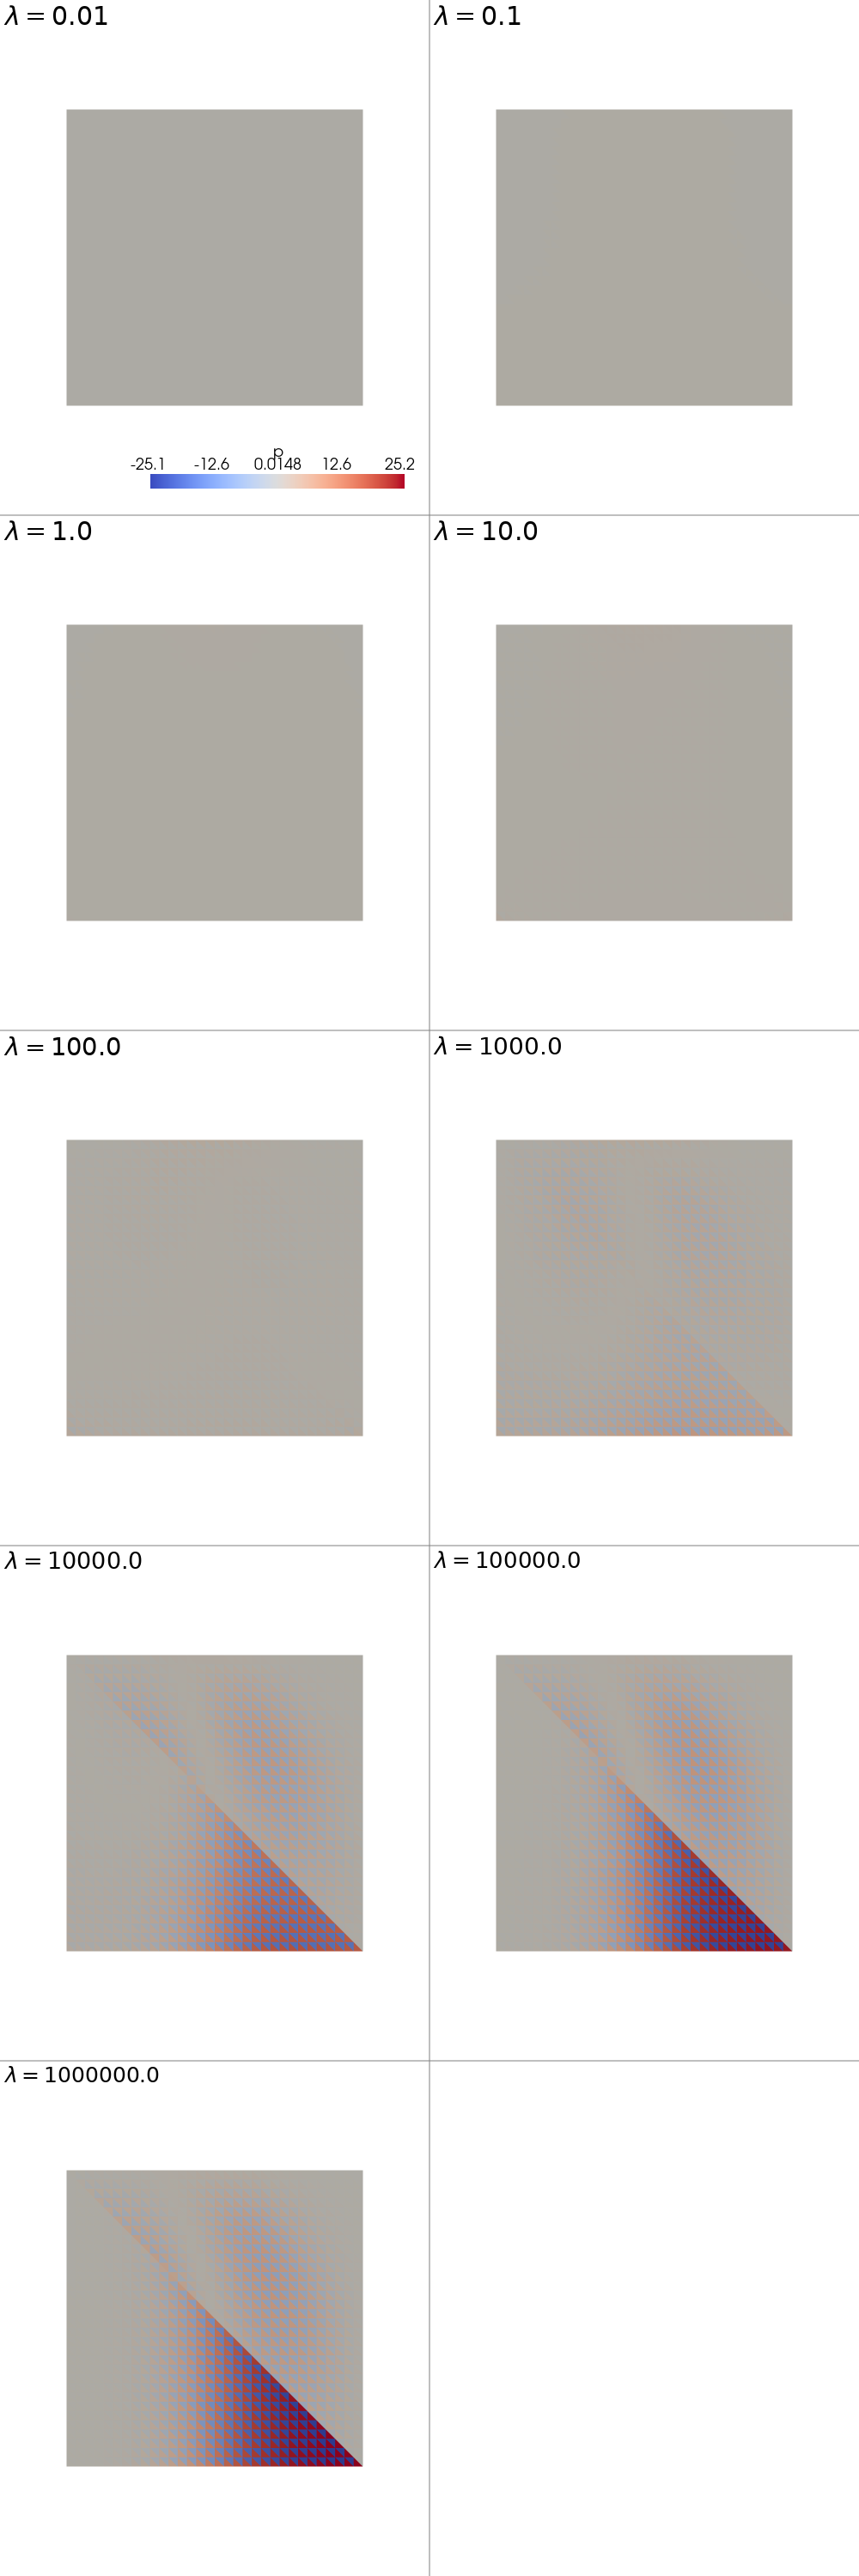

In [3]:
Vp = fd.FunctionSpace(mesh, 'DG', degree=0)

plotter3 = pv.Plotter(shape=(5, 2), window_size=(1000,3000))
for i, lamb in enumerate(lamblst):

    save_name = f"Solutions/ex_1_lamb={lamb}.pvd"

    # Solve on the original configuration
    uh = solve(
        mesh, Vh, mybcs, lamb,
        surface_force, body_force,
        save_name, True
    )
    p = fd.Function(Vp, name='p')
    p.project( - lamb *  fd.div(uh))

    
    VTKFile(
        f"Solutions/p_lamb={lamb}.pvd"
    ).write(p)

    grid = pv.read(f"Solutions/p_lamb={lamb}.pvd")
    grid = grid.combine(merge_points=True)
    p = grid.point_data["p"]

    plotter3.subplot(i//2, i%2)
    plotter3.add_mesh(grid, scalars="p", cmap="coolwarm", opacity=1.0, preference="cell", show_edges=False)
    plotter3.add_text(rf"$\lambda = {lamb}$", font_size=12)
    plotter3.view_xy()

plotter3.link_views()
plotter3.show()


## Exercise 4

    Residual norms for firedrake_30_ solve.
    0 KSP Residual norm 9.343083181260e-02
    1 KSP Residual norm 1.082147617935e-13
    Residual norms for firedrake_31_ solve.
    0 KSP Residual norm 6.973882308795e-02
    1 KSP Residual norm 1.575178439913e-14


/tmp/ipykernel_83153/2879175916.py:90: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter4.show()


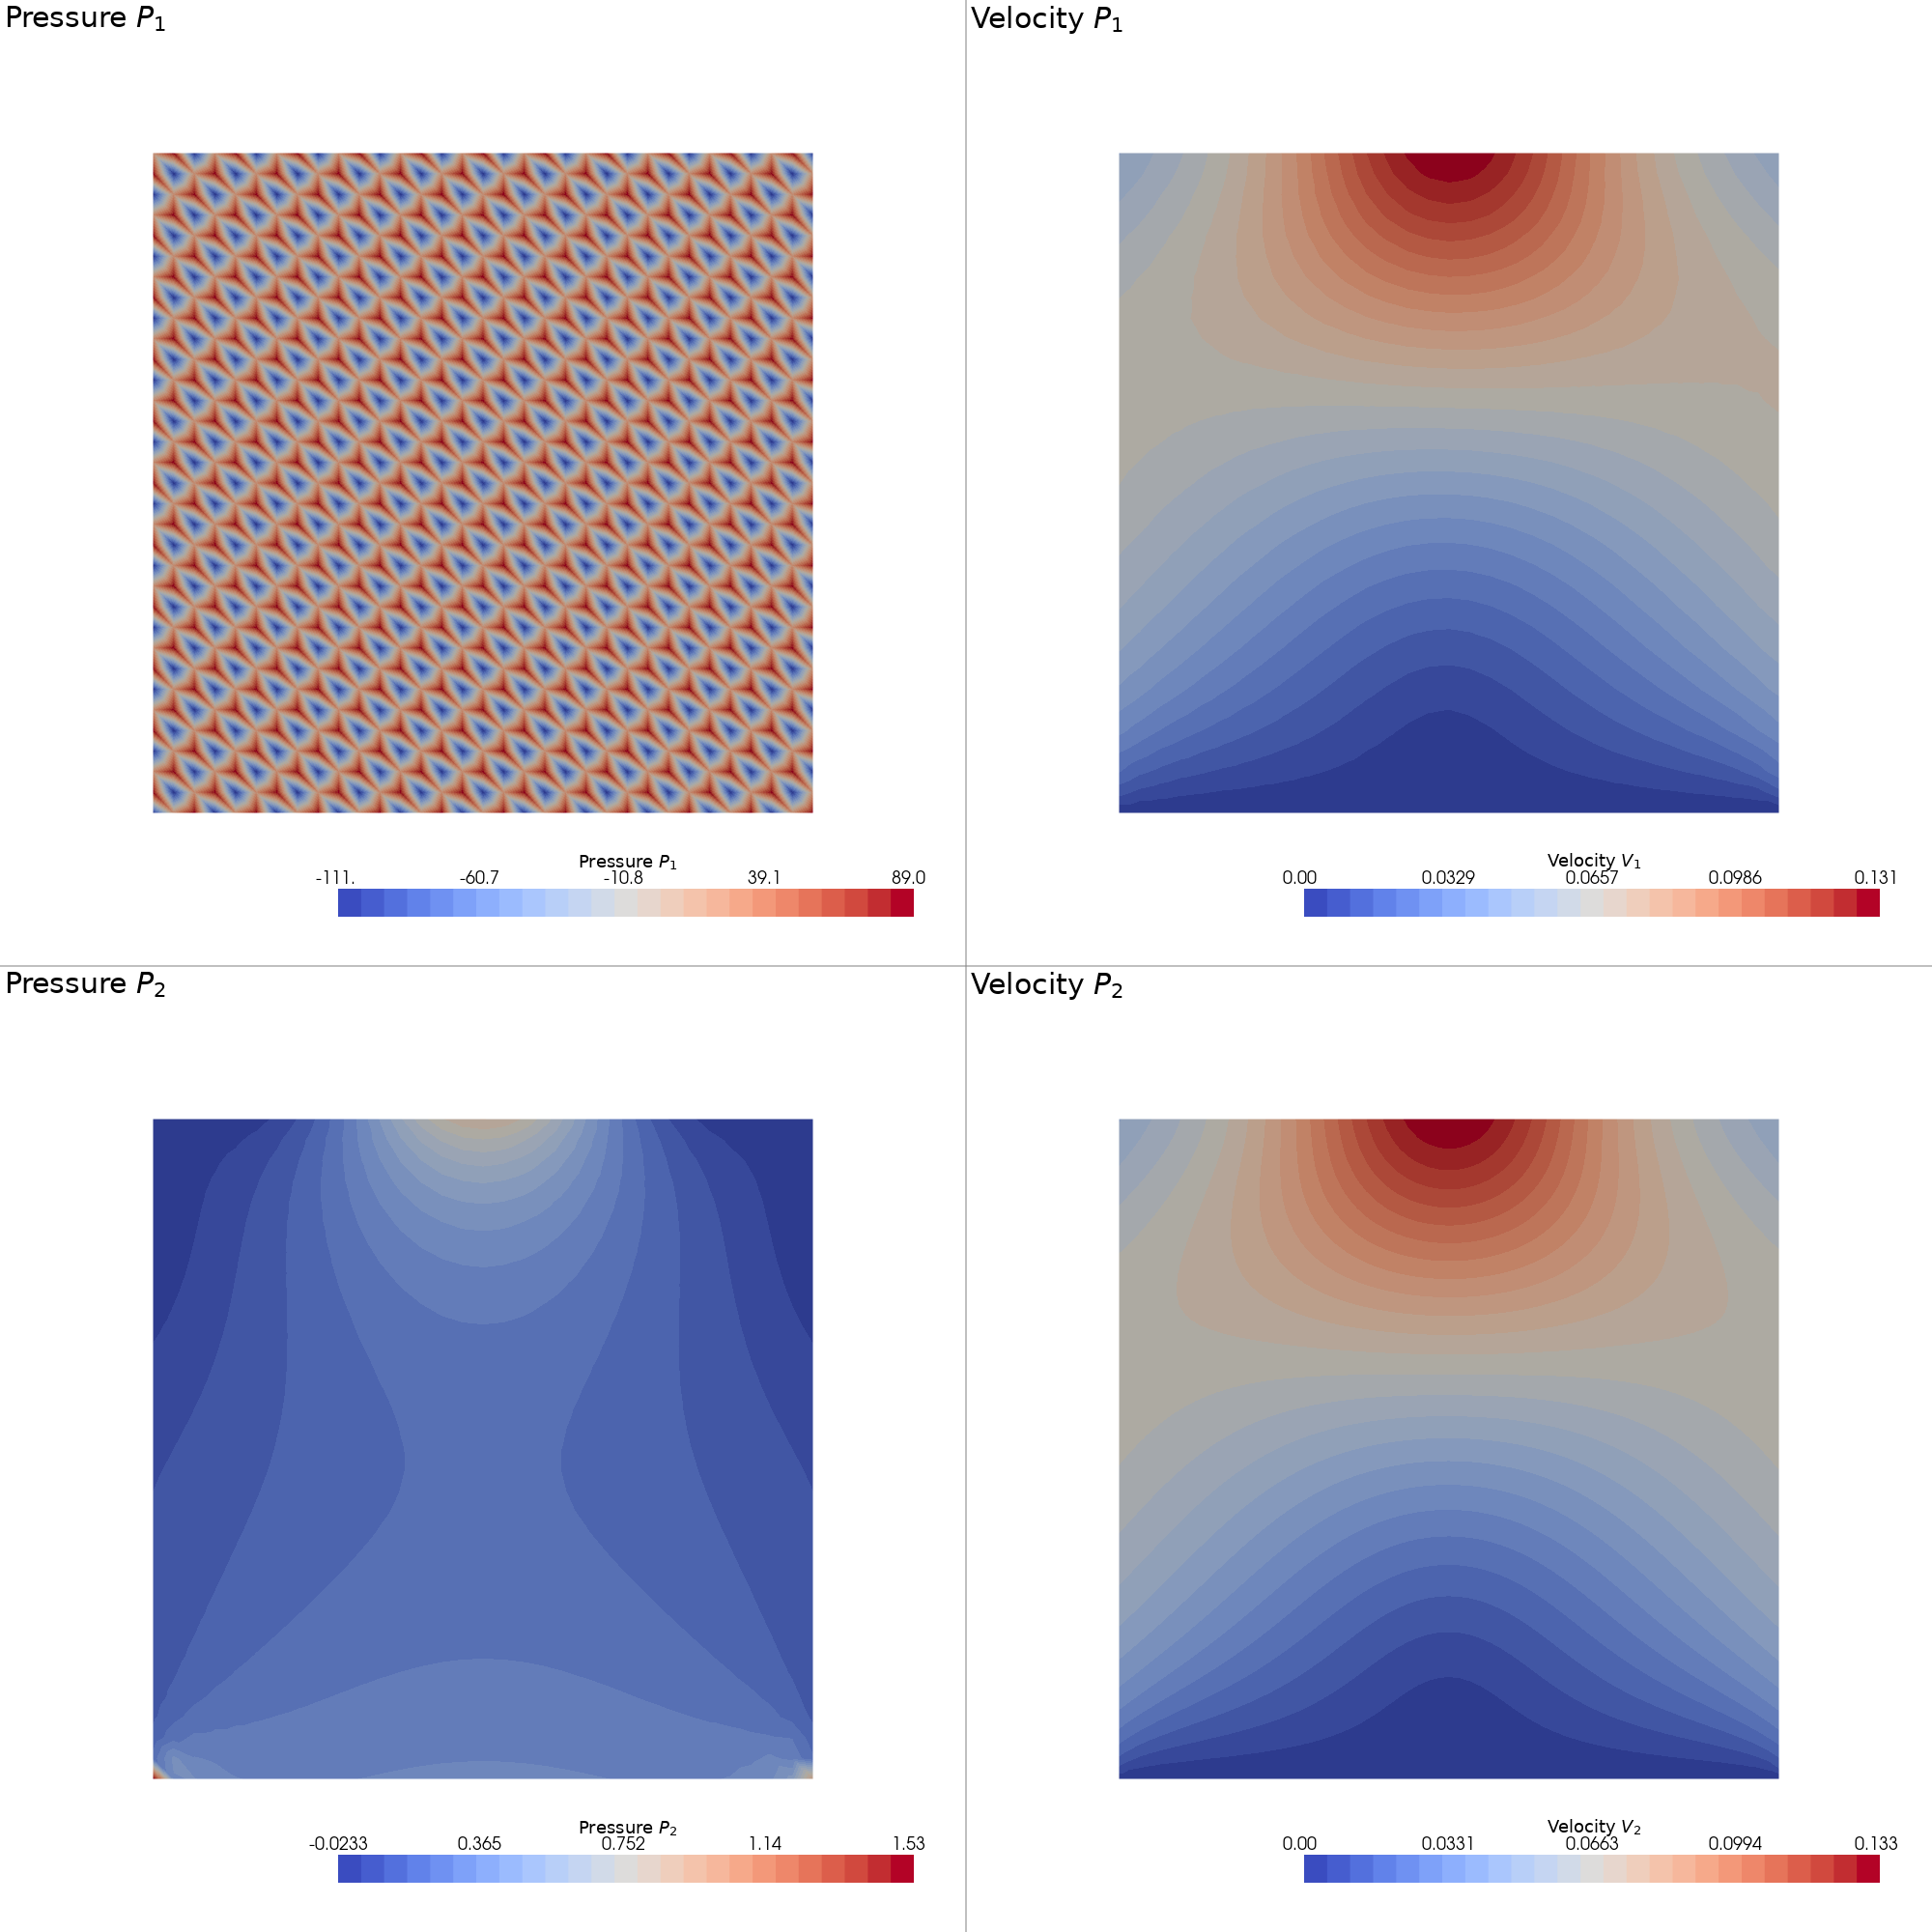

In [11]:
import firedrake as fd
from firedrake.output import VTKFile 
from firedrake.__future__ import interpolate 
import numpy as np
import pyvista as pv

# Finite element mesh
Nx, Ny = 32, 32
Lx, Ly = 1.0, 1.0
mymesh = fd.RectangleMesh(Nx, Ny, Lx, Ly, quadrilateral=False)
tags = {'Bottom': 3, 'Top': 4, 'Left': 1, 'Right': 2}

def viscosity(u):
    return fd.Constant(1.0)

x = fd.SpatialCoordinate(mymesh)

body_force = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])
surface_force = fd.as_vector([fd.Constant(0.0), -fd.exp(-20.0*(x[0]-0.5*Lx)**2)])
noslip = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])

mybcs = {'Bottom': noslip}

def SolveStokes(msh, bf, sf, bcs, u_degree):

    P2 = fd.VectorElement('Lagrange', 'triangle', u_degree)
    P1 = fd.FiniteElement('Lagrange', 'triangle', 1)
    TH = fd.MixedElement([P2,P1]) # Taylor-Hood
    Vh = fd.FunctionSpace(msh, TH)
    
    # Alternative way of defining it
    #P2 = fd.VectorFunctionSpace(msh, family="CG", degree=2)
    #P1 = fd.FunctionSpace(msh, family="CG", degree=1)
    #Vh = P2 * P1

    bclst = []
    for key in bcs:
        bclst.append(fd.DirichletBC(Vh.sub(0), bcs[key], tags[key]))
    
    sol = fd.Function(Vh)
    v, q = fd.TestFunctions(Vh)
    u, p = fd.split(sol)
    
    mu = viscosity(u)
    
    F  = mu * fd.inner((fd.grad(u) + fd.grad(u).T), fd.grad(v)) * fd.dx - p * fd.div(v) * fd.dx + q * fd.div(u) * fd.dx
    F -= fd.inner(bf, v) * fd.dx
    F -= fd.inner(sf, v) * fd.ds(tags['Top'])
    Jac = fd.derivative(F, sol)
    opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps", "ksp_monitor": None}
    fd.solve(F == 0, sol, bcs=bclst, J=Jac, solver_parameters=opts)

    return sol

plotter4 = pv.Plotter(shape=(2, 2), window_size=(2000,2000))
for i in [1,2]:
    sol = SolveStokes(mymesh, body_force, surface_force, mybcs, i)

    sol.sub(0).rename("Velocity")
    VTKFile(f"Solutions/velocity_P{i}.pvd").write(sol.sub(0))
    sol.sub(1).rename("Pressure")
    VTKFile(f"Solutions/pressure_P{i}.pvd").write(sol.sub(1))
    
    

    gridV = pv.read(f"Solutions/velocity_P{i}.pvd")
    gridP = pv.read(f"Solutions/pressure_P{i}.pvd")
    gridV = gridV.combine(merge_points=True)
    gridP = gridP.combine(merge_points=True)
    v = gridV.point_data["Velocity"]
    gridV.point_data["Magnitude"] = np.linalg.norm(v, axis=1)

    pmin = gridP.point_data["Pressure"].min()
    pmax = gridP.point_data["Pressure"].max()

    vmin = gridV.point_data["Magnitude"].min()
    vmax = gridV.point_data["Magnitude"].max()

    plotter4.subplot(i - 1, 0)
    plotter4.add_mesh(gridP, scalars="Pressure", cmap="coolwarm", opacity=1.0, show_edges=False, clim=(pmin,pmax), n_colors=25, show_scalar_bar=True, scalar_bar_args={"title": f"Pressure $P_{i}$"})
    plotter4.add_text(rf"Pressure $P_{i}$", font_size=12)
    plotter4.view_xy()

    plotter4.subplot(i - 1, 1)
    plotter4.add_mesh(gridV, scalars="Magnitude", cmap="coolwarm", opacity=1.0, show_edges=False, clim=(vmin,vmax), n_colors=25, show_scalar_bar=True, scalar_bar_args={"title": f"Velocity $V_{i}$"})
    plotter4.add_text(rf"Velocity $P_{i}$", font_size=12)
    plotter4.view_xy()

plotter4.link_views()
plotter4.show()


Using the pair $P_1 - P_1$, the pressure is spurious.  At the other hand, the velocity field using $P_1 - P_1$ is, qualitatively, the same as using $P_2 - P_1$.

## Exercise 5

    Residual norms for firedrake_11_ solve.
    0 KSP Residual norm 9.343083181260e-02
    1 KSP Residual norm 3.058396853289e-15


/tmp/ipykernel_100706/1754968903.py:100: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter5.show()


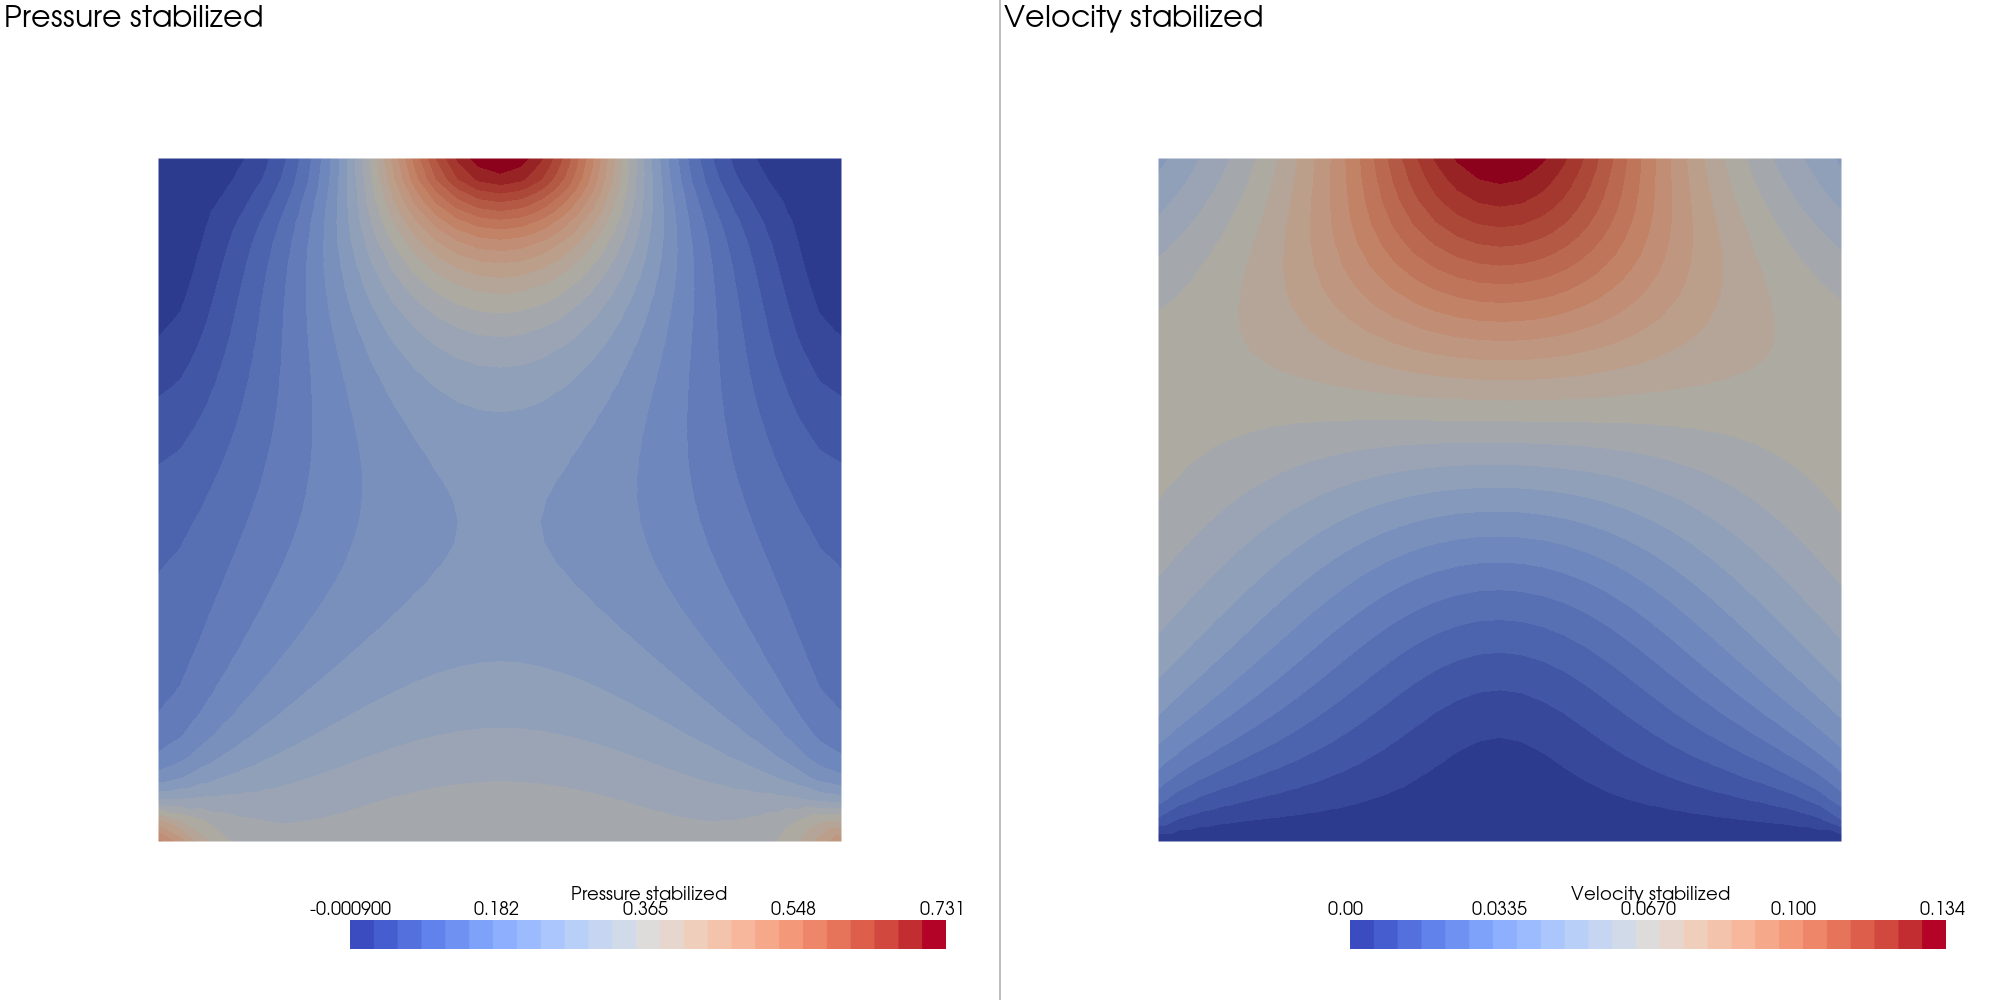

In [6]:
import firedrake as fd
from firedrake.output import VTKFile 
from firedrake.__future__ import interpolate 
import numpy as np
import pyvista as pv

# Finite element mesh
Nx, Ny = 32, 32
Lx, Ly = 1.0, 1.0
mymesh = fd.RectangleMesh(Nx, Ny, Lx, Ly, quadrilateral=False)
tags = {'Bottom': 3, 'Top': 4, 'Left': 1, 'Right': 2}

def viscosity(u):
    return fd.Constant(1.0)

x = fd.SpatialCoordinate(mymesh)

body_force = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])
surface_force = fd.as_vector([fd.Constant(0.0), -fd.exp(-20.0*(x[0]-0.5*Lx)**2)])
noslip = fd.as_vector([fd.Constant(0.0), fd.Constant(0.0)])

mybcs = {'Bottom': noslip}

def SolveStokes(msh, bf, sf, bcs):

    P2 = fd.VectorElement('Lagrange', 'triangle', 1)
    P1 = fd.FiniteElement('Lagrange', 'triangle', 1)
    TH = fd.MixedElement([P2,P1]) # Taylor-Hood
    Vh = fd.FunctionSpace(msh, TH)
    
    # Alternative way of defining it
    #P2 = fd.VectorFunctionSpace(msh, family="CG", degree=2)
    #P1 = fd.FunctionSpace(msh, family="CG", degree=1)
    #Vh = P2 * P1

    bclst = []
    for key in bcs:
        bclst.append(fd.DirichletBC(Vh.sub(0), bcs[key], tags[key]))
    
    sol = fd.Function(Vh)
    v, q = fd.TestFunctions(Vh)
    u, p = fd.split(sol)
    
    mu = viscosity(u)
    R = -fd.div(2.0 * mu * (fd.grad(u) + fd.grad(u).T)) + fd.grad(p) - bf

    P = -fd.div(2.0 * mu * (fd.grad(v) + fd.grad(v).T)) + fd.grad(q)

    h = fd.CellDiameter(msh)

    tau = h**2 / (4.0 * mu)
    
    
    F  = mu * fd.inner((fd.grad(u) + fd.grad(u).T), fd.grad(v)) * fd.dx - p * fd.div(v) * fd.dx + q * fd.div(u) * fd.dx
    F -= fd.inner(bf, v) * fd.dx
    F -= fd.inner(sf, v) * fd.ds(tags['Top'])
    F += tau * fd.inner(R, P) * fd.dx
    Jac = fd.derivative(F, sol)
    opts={"ksp_type": "preonly", "pc_type": "lu", "pc_factor_mat_solver_type": "mumps", "ksp_monitor": None}
    fd.solve(F == 0, sol, bcs=bclst, J=Jac, solver_parameters=opts)

    return sol


plotter5 = pv.Plotter(shape=(1, 2), window_size=(2000,1000))

sol = SolveStokes(mymesh, body_force, surface_force, mybcs)

sol.sub(0).rename("Velocity")
VTKFile(f"Solutions/velocity_stab.pvd").write(sol.sub(0))
sol.sub(1).rename("Pressure")
VTKFile(f"Solutions/pressure_stab.pvd").write(sol.sub(1))



gridV = pv.read(f"Solutions/velocity_stab.pvd")
gridP = pv.read(f"Solutions/pressure_stab.pvd")
gridV = gridV.combine(merge_points=True)
gridP = gridP.combine(merge_points=True)
v = gridV.point_data["Velocity"]
gridV.point_data["Magnitude"] = np.linalg.norm(v, axis=1)

pmin = gridP.point_data["Pressure"].min()
pmax = gridP.point_data["Pressure"].max()

vmin = gridV.point_data["Magnitude"].min()
vmax = gridV.point_data["Magnitude"].max()

plotter5.subplot(0, 0)
plotter5.add_mesh(gridP, scalars="Pressure", cmap="coolwarm", opacity=1.0, show_edges=False, clim=(pmin,pmax), n_colors=25, show_scalar_bar=True, scalar_bar_args={"title": f"Pressure stabilized"})
plotter5.add_text(rf"Pressure stabilized", font_size=12)
plotter5.view_xy()

plotter5.subplot(0, 1)
plotter5.add_mesh(gridV, scalars="Magnitude", cmap="coolwarm", opacity=1.0, show_edges=False, clim=(vmin,vmax), n_colors=25, show_scalar_bar=True, scalar_bar_args={"title": f"Velocity stabilized"})
plotter5.add_text(rf"Velocity stabilized", font_size=12)
plotter5.view_xy()

plotter5.link_views()
plotter5.show()
